In [141]:
import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, balanced_accuracy_score, precision_score
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer


from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import silhouette_score
import scipy.cluster.hierarchy as sch

import matplotlib.pyplot as plt
import seaborn as sb

from pathlib import Path
from IPython.display import display

import spacy

# SPACY_MODEL = 'en_core_web_sm' # or 'en_core_web_md'

In [44]:

#citanje podatak
df=pd.read_csv(Path.cwd().parent/'data'/'Womens Clothing E-Commerce Reviews.csv')

In [45]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Unnamed: 0               23486 non-null  int64 
 1   Clothing ID              23486 non-null  int64 
 2   Age                      23486 non-null  int64 
 3   Title                    19676 non-null  object
 4   Review Text              22641 non-null  object
 5   Rating                   23486 non-null  int64 
 6   Recommended IND          23486 non-null  int64 
 7   Positive Feedback Count  23486 non-null  int64 
 8   Division Name            23472 non-null  object
 9   Department Name          23472 non-null  object
 10  Class Name               23472 non-null  object
dtypes: int64(6), object(5)
memory usage: 2.0+ MB


In [46]:
#nad slučajnim uzorkom od 5000 komentara
df=df.sample(random_state=42,n=5000)

In [47]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5000 entries, 1297 to 6119
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Unnamed: 0               5000 non-null   int64 
 1   Clothing ID              5000 non-null   int64 
 2   Age                      5000 non-null   int64 
 3   Title                    4207 non-null   object
 4   Review Text              4845 non-null   object
 5   Rating                   5000 non-null   int64 
 6   Recommended IND          5000 non-null   int64 
 7   Positive Feedback Count  5000 non-null   int64 
 8   Division Name            4998 non-null   object
 9   Department Name          4998 non-null   object
 10  Class Name               4998 non-null   object
dtypes: int64(6), object(5)
memory usage: 468.8+ KB


In [48]:
df.isna().sum()

Unnamed: 0                   0
Clothing ID                  0
Age                          0
Title                      793
Review Text                155
Rating                       0
Recommended IND              0
Positive Feedback Count      0
Division Name                2
Department Name              2
Class Name                   2
dtype: int64

In [49]:
df.drop(columns='Unnamed: 0',inplace=True)

In [50]:
df.drop(columns='Clothing ID',inplace=True)

In [55]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4205 entries, 1297 to 6119
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Age                      4205 non-null   int64 
 1   Title                    4205 non-null   object
 2   Review Text              4205 non-null   object
 3   Rating                   4205 non-null   int64 
 4   Recommended IND          4205 non-null   int64 
 5   Positive Feedback Count  4205 non-null   int64 
 6   Division Name            4205 non-null   object
 7   Department Name          4205 non-null   object
 8   Class Name               4205 non-null   object
 9   review_content           4205 non-null   object
dtypes: int64(4), object(6)
memory usage: 361.4+ KB


In [52]:
df=df.dropna()

In [53]:
df['review_content']=df['Title']+'. ' +  df['Review Text']

In [54]:
df.review_content

1297     Size up if busty. I agree with the other revie...
7228     Snap front hoodie. I have many sweaters but i ...
21410    Adorable. Beautiful top but runs a whole size ...
8358     Fraying after 2 wears!. I loved these pants.th...
20840    Fabulous material..... I ordered this dress in...
                               ...                        
13815    Fun and flirty. Love! color and fabric are bea...
11643    Print ?. The print doesn't necessarily works f...
2958     Beautiful special occasion dress. I bought thi...
21255    Casual and comfortable. This dress fits well a...
6119     Great winter basic!. This dress is by no means...
Name: review_content, Length: 4205, dtype: object

In [57]:
def rating_to_sentiment(rating):
    if rating >3:
        return "positive"
    if rating <3:
        return "negative"
    return 'neutral'

In [58]:
df['sentiment']=df.Rating.apply(rating_to_sentiment)

In [61]:
df.sentiment.value_counts()
#mozemo da vidimo da imamo problem kod dataseta imamo previse positivnih reviewea 6 puta vise nego neutralnih ili negativnih , samim tim model ce sigurno bolje prepoznativi pozitivne reviewe.

#positive 3231 /4205 = 0,76%
#neutral 558 /4205 = 0,13%
#negative 416/4205 = 0,10%

sentiment
positive    3231
neutral      558
negative     416
Name: count, dtype: int64

In [64]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4205 entries, 1297 to 6119
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Age                      4205 non-null   int64 
 1   Title                    4205 non-null   object
 2   Review Text              4205 non-null   object
 3   Rating                   4205 non-null   int64 
 4   Recommended IND          4205 non-null   int64 
 5   Positive Feedback Count  4205 non-null   int64 
 6   Division Name            4205 non-null   object
 7   Department Name          4205 non-null   object
 8   Class Name               4205 non-null   object
 9   review_content           4205 non-null   object
 10  sentiment                4205 non-null   object
dtypes: int64(4), object(7)
memory usage: 394.2+ KB


In [65]:
df.head()

,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name,review_content,sentiment
1297,34,Size up if busty,I agree with the other reviewer that the color...,4,1,19,General,Dresses,Dresses,Size up if busty. I agree with the other revie...,positive
7228,57,Snap front hoodie,I have many sweaters but i bought this during ...,4,1,0,General Petite,Tops,Fine gauge,Snap front hoodie. I have many sweaters but i ...,positive
21410,56,Adorable,Beautiful top but runs a whole size small. gav...,4,1,3,General,Tops,Blouses,Adorable. Beautiful top but runs a whole size ...,positive
8358,36,Fraying after 2 wears!,I loved these pants.they are so comfortable. h...,3,0,3,General Petite,Bottoms,Pants,Fraying after 2 wears!. I loved these pants.th...,neutral
20840,30,Fabulous material....,I ordered this dress in a petite but it arrive...,5,1,0,General,Dresses,Dresses,Fabulous material..... I ordered this dress in...,positive


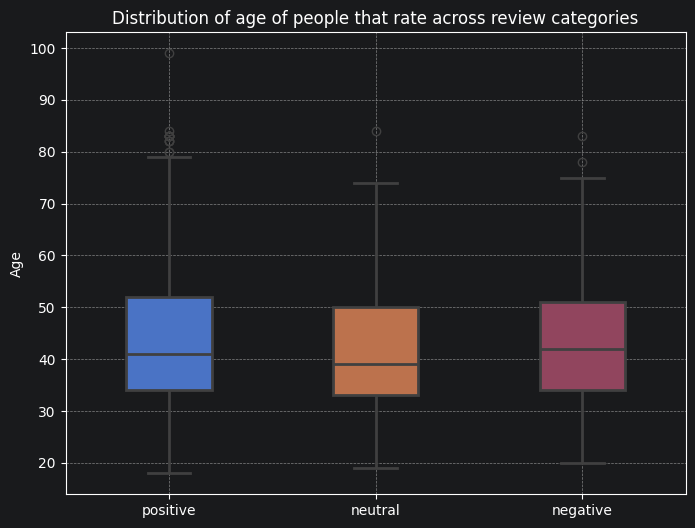

In [79]:
plt.figure(figsize=(8, 6))

sb.boxplot(data=df, x='sentiment', y='Age', hue='sentiment', fill=True, saturation=0.75, width=0.55, gap=0.25, linewidth=2, legend=False)

plt.title('Distribution of age of people that rate across review categories')
plt.ylabel('Age')
plt.xlabel('')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [ ]:
#Raspodela starosti su skore iste za sve tri klase sentimenta , krive u kdeplotu su skoro potpuno preklapaju , a medijane na boxplotu su skkoro na istoj vrednosti 39-42 se krecu na skali do od 1 do 100 .. Starost kupca i kolona Age ne pomaze modelu da razlikuje sentimente i ne ukljucujemo je u model .


In [84]:
df['Recommended IND'].value_counts()

Recommended IND
1    3451
0     754
Name: count, dtype: int64

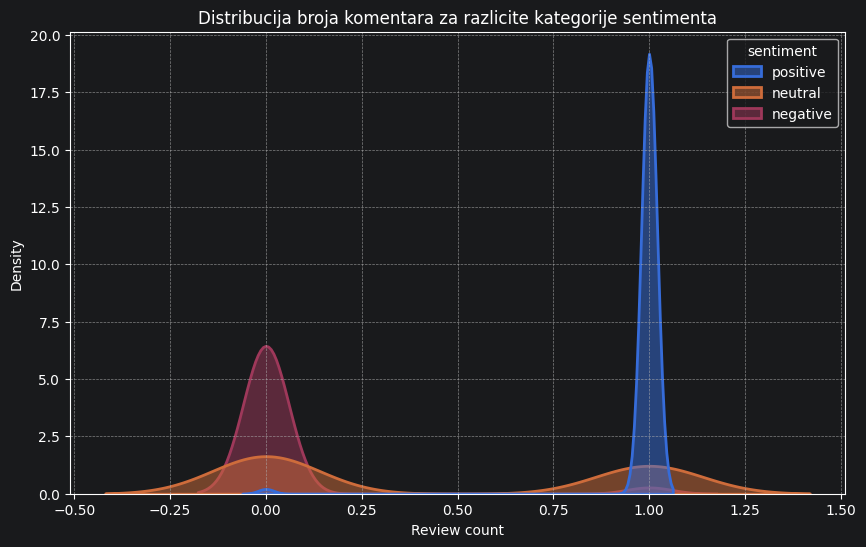

In [89]:
plt.figure(figsize=(10, 6))

sb.kdeplot(data=df,
           x='Recommended IND',
           hue='sentiment',
           fill=True,
           common_norm=False,
           alpha=0.5,
           linewidth=2)

plt.title('Distribucija da li je korisnik preporucio proizvod za razlicite kategorije sentimenta')
plt.xlabel('Review count')
plt.ylabel('Density')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [ ]:
# ova kolona savresno razdvaja podatke ali je curenje podataka koje se dobija kada korisnik zapravo rateje proizvod samim tim ne smemo da je koristimo kao feature


In [90]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4205 entries, 1297 to 6119
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Age                      4205 non-null   int64 
 1   Title                    4205 non-null   object
 2   Review Text              4205 non-null   object
 3   Rating                   4205 non-null   int64 
 4   Recommended IND          4205 non-null   int64 
 5   Positive Feedback Count  4205 non-null   int64 
 6   Division Name            4205 non-null   object
 7   Department Name          4205 non-null   object
 8   Class Name               4205 non-null   object
 9   review_content           4205 non-null   object
 10  sentiment                4205 non-null   object
dtypes: int64(4), object(7)
memory usage: 394.2+ KB


In [93]:
df['Positive Feedback Count'].describe()

count    4205.000000
mean        2.555767
std         5.641742
min         0.000000
25%         0.000000
50%         1.000000
75%         3.000000
max       108.000000
Name: Positive Feedback Count, dtype: float64

<Axes: ylabel='Positive Feedback Count'>

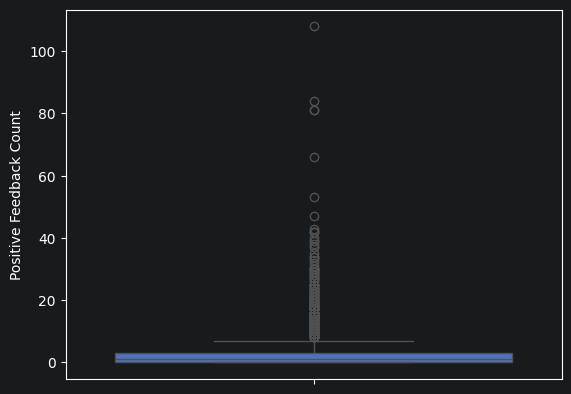

In [94]:
plt.figure()
sb.boxplot(df['Positive Feedback Count'])

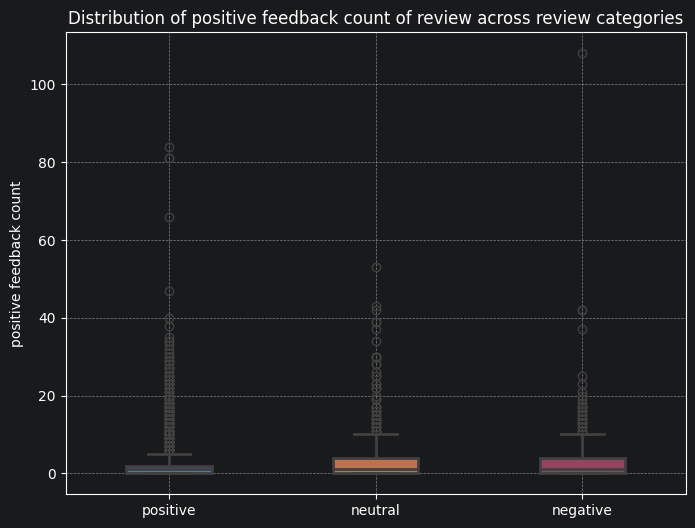

In [96]:
plt.figure(figsize=(8, 6))

sb.boxplot(data=df, x='sentiment', y='Positive Feedback Count', hue='sentiment', fill=True, saturation=0.75, width=0.55, gap=0.25, linewidth=2, legend=False)

plt.title('Distribution of positive feedback count of review across review categories')
plt.ylabel('positive feedback count')
plt.xlabel('')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

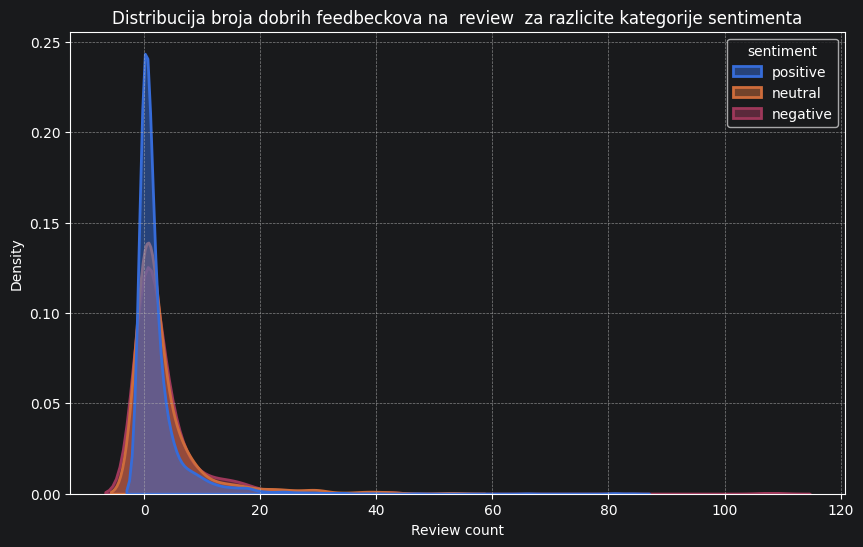

In [97]:
plt.figure(figsize=(10, 6))

sb.kdeplot(data=df,
           x='Positive Feedback Count',
           hue='sentiment',
           fill=True,
           common_norm=False,
           alpha=0.5,
           linewidth=2)

plt.title('Distribucija broja dobrih feedbeckova na  review  za razlicite kategorije sentimenta')
plt.xlabel('Review count')
plt.ylabel('Density')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [98]:
#Pozitivni komentari uglavnom imaju 0 do 2 pozitivna glasa, dok neutralni i negativni češće dobijaju više glasova (gornji kvartil oko 4 naspram 2). Razlika nije velika, ali postoji, pa kolonu uključujemo u model.

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4205 entries, 1297 to 6119
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Age                      4205 non-null   int64 
 1   Title                    4205 non-null   object
 2   Review Text              4205 non-null   object
 3   Rating                   4205 non-null   int64 
 4   Recommended IND          4205 non-null   int64 
 5   Positive Feedback Count  4205 non-null   int64 
 6   Division Name            4205 non-null   object
 7   Department Name          4205 non-null   object
 8   Class Name               4205 non-null   object
 9   review_content           4205 non-null   object
 10  sentiment                4205 non-null   object
dtypes: int64(4), object(7)
memory usage: 394.2+ KB


In [99]:
df['Division Name'].value_counts()

Division Name
General           2483
General Petite    1472
Initmates          250
Name: count, dtype: int64

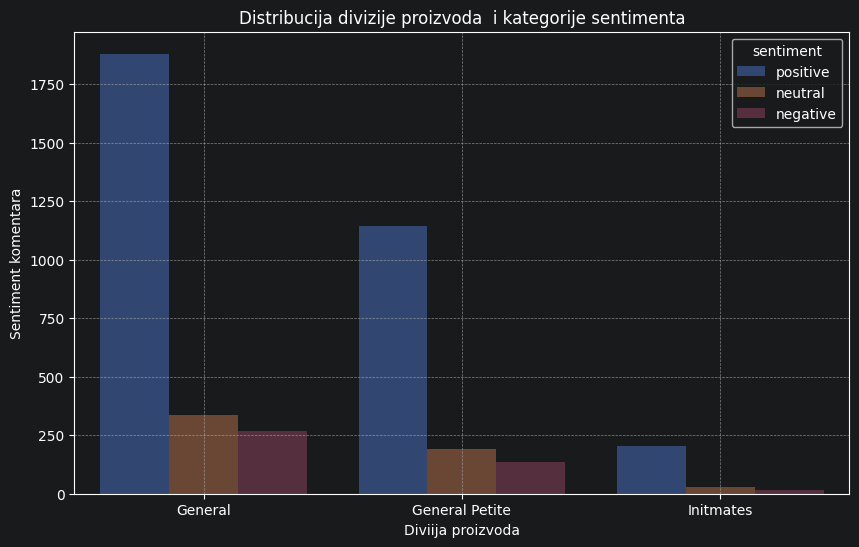

In [102]:
plt.figure(figsize=(10, 6))

sb.countplot(data=df,
           x='Division Name',
           hue='sentiment',
           fill=True,
           alpha=0.5)

plt.title('Distribucija divizije proizvoda  i kategorije sentimenta')
plt.xlabel('Diviija proizvoda')
plt.ylabel('Sentiment komentara')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [105]:
print(pd.crosstab(df['Division Name'], df['sentiment'], normalize='index').round(2))


sentiment       negative  neutral  positive
Division Name                              
General             0.11     0.14      0.76
General Petite      0.09     0.13      0.78
Initmates           0.06     0.12      0.82


In [ ]:
#Udeli sentimenata su slični u svim divizijama: pozitivnih je 76–82%, neutralnih 12–14%, a negativnih 6–11%. Divizija proizvoda zato ne pomaže u razlikovanju sentimenta i ne uključujemo je u model.


In [107]:
df['Department Name'].value_counts()

Department Name
Tops        1847
Dresses     1181
Bottoms      689
Intimate     292
Jackets      174
Trend         22
Name: count, dtype: int64

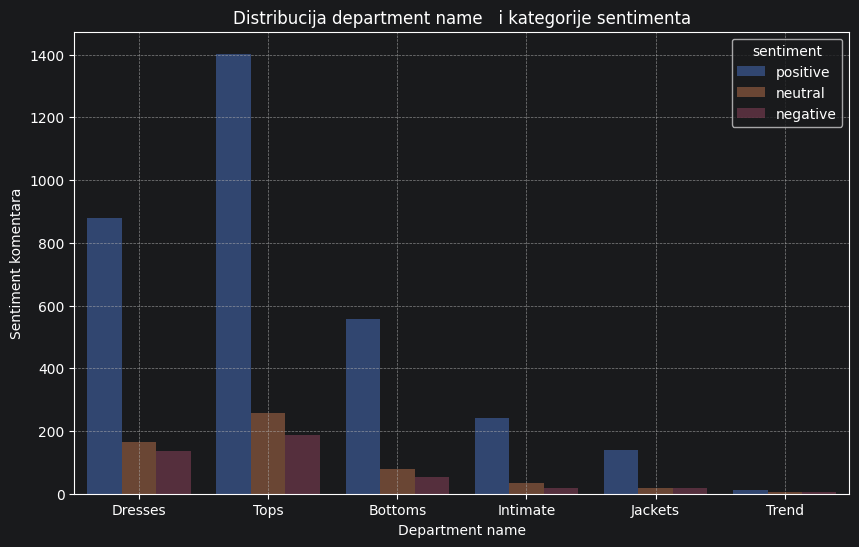

In [110]:
plt.figure(figsize=(10, 6))

sb.countplot(data=df,
           x='Department Name',
           hue='sentiment',
           fill=True,
           alpha=0.5)

plt.title('Distribucija department name   i kategorije sentimenta')
plt.xlabel('Department name')
plt.ylabel('Sentiment komentara')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [116]:
print(pd.crosstab(df['Department Name'],df['sentiment'],normalize="index").round(2))

sentiment        negative  neutral  positive
Department Name                             
Bottoms              0.08     0.11      0.81
Dresses              0.12     0.14      0.74
Intimate             0.06     0.11      0.83
Jackets              0.10     0.10      0.80
Tops                 0.10     0.14      0.76
Trend                0.23     0.27      0.50


In [117]:
print(df['Department Name'].value_counts())

Department Name
Tops        1847
Dresses     1181
Bottoms      689
Intimate     292
Jackets      174
Trend         22
Name: count, dtype: int64


In [ ]:
#ovo ukljucujemo u model zato jer ima malih razlika u raspodelama naravno uz onehot enocovanje ...

In [118]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4205 entries, 1297 to 6119
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Age                      4205 non-null   int64 
 1   Title                    4205 non-null   object
 2   Review Text              4205 non-null   object
 3   Rating                   4205 non-null   int64 
 4   Recommended IND          4205 non-null   int64 
 5   Positive Feedback Count  4205 non-null   int64 
 6   Division Name            4205 non-null   object
 7   Department Name          4205 non-null   object
 8   Class Name               4205 non-null   object
 9   review_content           4205 non-null   object
 10  sentiment                4205 non-null   object
dtypes: int64(4), object(7)
memory usage: 394.2+ KB


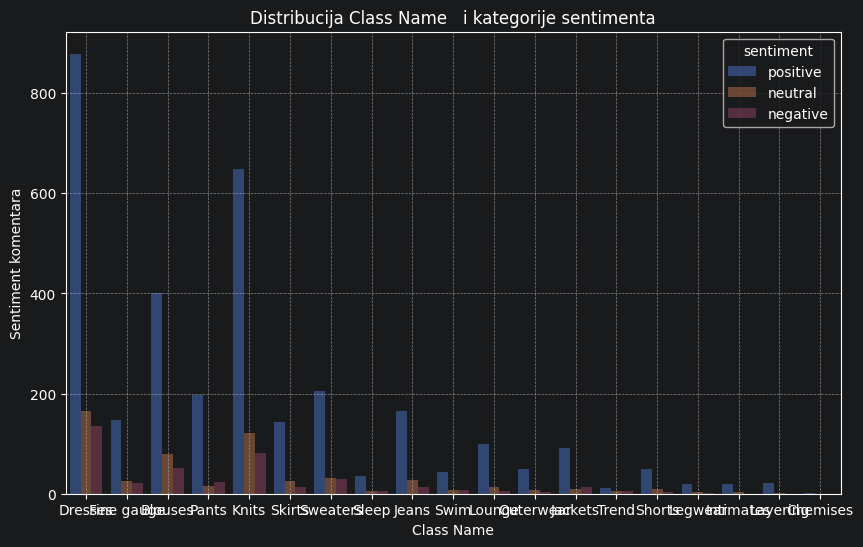

In [119]:
plt.figure(figsize=(10, 6))

sb.countplot(data=df,
           x='Class Name',
           hue='sentiment',
           fill=True,
           alpha=0.5)

plt.title('Distribucija Class Name   i kategorije sentimenta')
plt.xlabel('Class Name')
plt.ylabel('Sentiment komentara')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [120]:
print(pd.crosstab(df['Class Name'],df['sentiment'],normalize="index").round(2))

sentiment   negative  neutral  positive
Class Name                             
Blouses         0.10     0.15      0.75
Chemises        0.00     0.00      1.00
Dresses         0.12     0.14      0.74
Fine gauge      0.11     0.13      0.76
Intimates       0.00     0.13      0.87
Jackets         0.12     0.09      0.79
Jeans           0.06     0.14      0.80
Knits           0.10     0.14      0.76
Layering        0.00     0.05      0.95
Legwear         0.04     0.12      0.83
Lounge          0.04     0.12      0.84
Outerwear       0.05     0.12      0.83
Pants           0.10     0.07      0.83
Shorts          0.05     0.15      0.81
Skirts          0.08     0.14      0.79
Sleep           0.11     0.11      0.78
Sweaters        0.11     0.12      0.77
Swim            0.12     0.12      0.75
Trend           0.23     0.27      0.50


In [ ]:
#one hot encodiranje bi uvelo previse novih kolona , klasa proizvoda je bolkja podela nego class name pa ovo ne ukljucujemo ...

In [121]:
df.info()


<class 'pandas.core.frame.DataFrame'>
Index: 4205 entries, 1297 to 6119
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Age                      4205 non-null   int64 
 1   Title                    4205 non-null   object
 2   Review Text              4205 non-null   object
 3   Rating                   4205 non-null   int64 
 4   Recommended IND          4205 non-null   int64 
 5   Positive Feedback Count  4205 non-null   int64 
 6   Division Name            4205 non-null   object
 7   Department Name          4205 non-null   object
 8   Class Name               4205 non-null   object
 9   review_content           4205 non-null   object
 10  sentiment                4205 non-null   object
dtypes: int64(4), object(7)
memory usage: 394.2+ KB


In [122]:
X=df[['Department Name','Positive Feedback Count','review_content']]
y=df['sentiment']

In [123]:
X

,Department Name,Positive Feedback Count,review_content
1297,Dresses,19,Size up if busty. I agree with the other revie...
7228,Tops,0,Snap front hoodie. I have many sweaters but i ...
21410,Tops,3,Adorable. Beautiful top but runs a whole size ...
8358,Bottoms,3,Fraying after 2 wears!. I loved these pants.th...
20840,Dresses,0,Fabulous material..... I ordered this dress in...
...,...,...,...
13815,Dresses,0,Fun and flirty. Love! color and fabric are bea...
11643,Tops,0,Print ?. The print doesn't necessarily works f...
2958,Dresses,1,Beautiful special occasion dress. I bought thi...
21255,Intimate,0,Casual and comfortable. This dress fits well a...


In [124]:
y

1297     positive
7228     positive
21410    positive
8358      neutral
20840    positive
           ...   
13815    positive
11643    negative
2958     positive
21255    positive
6119     positive
Name: sentiment, Length: 4205, dtype: object

In [126]:
nlp=spacy.load('en_core_web_sm')

In [127]:
tokeniProba=nlp('ja sam vukasin')

In [134]:
def spacy_sredi_tekst(doc):
    ociscenTekst=[]
    tokens=nlp(doc)
    for token in tokens:
        lemma_lower=token.lemma_.lower()
        if token.is_punct or token.is_space or token.like_num or token.like_url or token.like_email:
            continue
        if token.is_stop and lemma_lower!="not":
            continue
        ociscenTekst.append(lemma_lower)
    return ociscenTekst

In [136]:
vectorizer=TfidfVectorizer(token_pattern=None,tokenizer=spacy_sredi_tekst,ngram_range=(1,2),max_df=0.95,min_df=0.01)

In [132]:
scaler=RobustScaler()

In [133]:
one_hot_encoder=OneHotEncoder(handle_unknown='ignore')

In [137]:
col_transformer=ColumnTransformer([
    ('vectorizer',vectorizer,'review_content'),
    ('scaler',scaler,['Positive Feedback Count']),
    ('encoder',one_hot_encoder,['Department Name'])
])

In [138]:
y_embeddings,y_levels=pd.factorize(y)

In [139]:
y_levels

Index(['positive', 'neutral', 'negative'], dtype='object')

In [140]:
X_train, X_test, y_train, y_test = train_test_split(X, y_embeddings, test_size=0.2, random_state=42,stratify=y_embeddings)

In [142]:
pipe=Pipeline([
    ('transformer',col_transformer),
    ('cls',LogisticRegression(max_iter=2000))
])

In [143]:
pipe.fit(X_train,y_train)

,steps,"[('transformer', ...), ('cls', ...)]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('vectorizer', ...), ('scaler', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatti

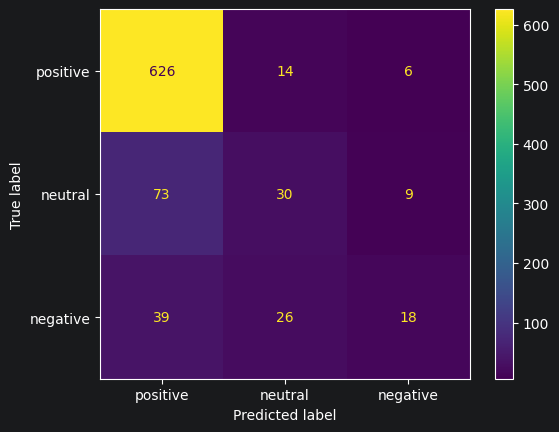

In [147]:
ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test,display_labels=y_levels)
plt.show()

In [ ]:
#pogodili smo 626 stvarno pozitivinih za koje smo rekli da su stvarno pozitvni , ali dosta puta smo rekli da je nesto pozivitno a bilo je ili neutralno ili negativno preko 112 puta ... model je preucio pozivitnu klasu ... vidimo da nemamo ni dosta neutralnih i negativnih sentimenata samim tim data set i test skup nije bio balansiran ... ...

In [148]:
y_pred=pipe.predict(X_test)

In [150]:
print(classification_report(y_test, y_pred, target_names=y_levels))

              precision    recall  f1-score   support

    positive       0.85      0.97      0.90       646
     neutral       0.43      0.27      0.33       112
    negative       0.55      0.22      0.31        83

    accuracy                           0.80       841
   macro avg       0.61      0.48      0.51       841
weighted avg       0.76      0.80      0.77       841



In [ ]:
#vidimo da smo ostvarili za pozitivnu klasu dobar f1 score koji je zapravo balans preccinznosti i recalla koji su veliki , ali nam rezultati nisu bas dobri za neutralnu i negativni klasu gde nam je f1score oko 0.30 ... sto je dosta slabo ... pametno bi bilo napraviti da ovaj dataset bude malo uravnotezniji rezultatit su ovakvi jer je model preucio na pozitivnoj klasi ...

In [152]:
balanced_accuracy_score(y_test, y_pred)

0.4845882868048932

In [ ]:
#ballanced accuarcy je u ovom slucaju 0.4845: a definisan kao average of recall obtained on each class.

In [155]:
#macro average preciznosti je definisan kao obican prosek prezonosti svih klasa i iznosti 61 , weighted average precision je definisan kao teziniska preciznost i iznosi 0.76 ...

In [159]:
from sklearn.metrics import precision_recall_fscore_support # hocu da dodas ovo kao jako bitno u delu gde u htmolovima pricamo o evaluacijama ovde su mi formule ovoga jer treba dase objasni i dopise ...

In [160]:
# The precision is the ratio ``tp / (tp + fp)`` where ``tp`` is the number of
#     true positives and ``fp`` the number of false positives. The precision is
#     intuitively the ability of the classifier not to label a negative sample as
#     positive.
#
#     The recall is the ratio ``tp / (tp + fn)`` where ``tp`` is the number of
#     true positives and ``fn`` the number of false negatives. The recall is
#     intuitively the ability of the classifier to find all the positive samples.
#
#     The F-beta score can be interpreted as a weighted harmonic mean of
#     the precision and recall, where an F-beta score reaches its best
#     value at 1 and worst score at 0.
#
#     The F-beta score weights recall more than precision by a factor of
#     ``beta``. ``beta == 1.0`` means recall and precision are equally important.

Help on function precision_recall_fscore_support in module sklearn.metrics._classification:

precision_recall_fscore_support(
    y_true,
    y_pred,
    *,
    beta=1.0,
    labels=None,
    pos_label=1,
    average=None,
    warn_for=('precision', 'recall', 'f-score'),
    sample_weight=None,
    zero_division='warn'
)
    Compute precision, recall, F-measure and support for each class.

    The precision is the ratio ``tp / (tp + fp)`` where ``tp`` is the number of
    true positives and ``fp`` the number of false positives. The precision is
    intuitively the ability of the classifier not to label a negative sample as
    positive.

    The recall is the ratio ``tp / (tp + fn)`` where ``tp`` is the number of
    true positives and ``fn`` the number of false negatives. The recall is
    intuitively the ability of the classifier to find all the positive samples.

    The F-beta score can be interpreted as a weighted harmonic mean of
    the precision and recall, where an F-beta scor

In [ ]:
parametri={
    'transformer__vectorizer__min_df':[0.005,0.01,0.02],
    'cls__C':[0.1,1,10],
    'cls__class_weight':[None,'balanced']
}

grid_search=GridSearchCV(pipe,param_grid=parametri,verbose=2,cv=5,scoring='f1_macro')
grid_search.fit(X_train,y_train)
print(grid_search.best_params_)

Fitting 5 folds for each of 18 candidates, totalling 90 fits
[CV] END cls__C=0.1, cls__class_weight=None, transformer__vectorizer__min_df=0.005; total time=  48.0s
[CV] END cls__C=0.1, cls__class_weight=None, transformer__vectorizer__min_df=0.005; total time=  48.9s


KeyboardInterrupt: 